# Reading **TELEMAC Selafin (`.slf`)** results with `pyramids-mesh`

**Selafin** (a.k.a. SERAFIN) is the binary mesh-and-results format of the **TELEMAC-MASCARET** hydrodynamic suite. Unlike a pure geometry format, a Selafin file bundles the triangular mesh **and** one or more time-varying variables (water depth, velocity, …). `pyramids-mesh` registers a `selafin` driver that parses both the topology and the variables into a `UgridDataset`.

The bundled `minimal.slf` carries a **WATER DEPTH** variable over two time steps on a two-triangle mesh. We read it and map the depth field.

## 3. Locate the data

`minimal.slf` lives in `examples/data/`, two levels up; addressed as a `Path`.

In [1]:
from pathlib import Path
DATA = Path("../../examples/data")
print((DATA / "minimal.slf").resolve())

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\examples\data\minimal.slf


## 1. Plotting backend and a `show()` helper

`pyramids` renders through `cleopatra`, which forces matplotlib's non-interactive **`Agg`** backend. Under `Agg` a bare `plt.show()` embeds *nothing* when the notebook is executed headless (as CI does). So we pin `Agg` explicitly before importing `pyplot`.

In [2]:
import os
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display

Next a tiny `show()` helper: it grabs the current figure, writes it to an in-memory PNG, and `display()`s that — guaranteeing every plot lands in the saved notebook. We call `show()` right after each plotting call.

In [3]:
def show():
    """Embed the current matplotlib figure as a PNG (Agg draws nothing on its own)."""
    from io import BytesIO
    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all")
    buf.seek(0)
    display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [4]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np

## 4. Read the file

A Selafin file is self-contained — mesh plus results — so a single `read_file` yields a dataset that already has a data variable. A driver's only job is to parse the file and hand back a `UgridDataset`. We pass a `pathlib.Path` (never a `str`) and name the `driver` explicitly:

In [5]:
ds = UgridDataset.read_file(DATA / "minimal.slf", driver="selafin")
ds

UgridDataset(mesh='mesh2d', n_node=4, n_face=2, n_edge=0, variables=['WATER DEPTH'])

## 5. Explore the dataset

A `UgridDataset` exposes the mesh size, its coordinate reference system, and the data variables carried alongside the topology. `None` for `crs`/`epsg` simply means the source file declared no projection — the geometry is still valid, it is just unlocated in world space.

In [6]:
print('nodes :', ds.n_node)
print('faces :', ds.n_face)
print('crs   :', ds.crs)
print('epsg  :', ds.epsg)
print('vars  :', ds.data_variable_names)
print('bounds:', ds.bounds)

nodes : 4
faces : 2
crs   : None
epsg  : None
vars  : ['WATER DEPTH']
bounds: (0.0, 0.0, 1.0, 1.0)


### Per-variable summary

`ds.summary()` returns a pandas `DataFrame` — one row per data variable with count, min, max, mean and standard deviation. A `std` of 0 means that variable is uniform across the mesh.

In [7]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
WATER DEPTH,8,0.125,1.75,0.90625,0.554632


### Global attributes

Each driver stamps provenance into `global_attributes` so you can trace a dataset back to the format it came from after it has been converted.

In [8]:
ds.global_attributes

{'source': 'TELEMAC Selafin', 'n_timesteps': 2}

Note the `n_timesteps` entry in the global attributes above and the `WATER DEPTH` entry in `data_variable_names`: TELEMAC's time series came through intact.

## 6. The `Mesh2d` geometry

`ds.mesh` is a `Mesh2d`: node coordinates plus the face-node connectivity table. `face_node_connectivity.data` has shape `(n_face, k)` — row *i* lists the node indices of face *i* (padded for mixed element types). We also derive per-face areas and centroids from that topology.

In [9]:
m = ds.mesh
print('node_x shape           :', np.asarray(m.node_x).shape)
print('connectivity shape     :', np.asarray(m.face_node_connectivity.data).shape)
print('face_areas shape       :', np.asarray(m.face_areas).shape)
centroids = np.asarray(m.face_centroids)  # shape (2, n_face)
print('face_centroids shape   :', centroids.shape)
print('first face areas       :', np.asarray(m.face_areas)[:3])

node_x shape           : (4,)
connectivity shape     : (2, 3)
face_areas shape       : (2,)
face_centroids shape   : (2, 2)
first face areas       : [0.5 0.5]


## 7. Wireframe — the mesh skeleton

`plot_outline()` draws the bare mesh: every face edge, no data coloring. This is the fastest way to eyeball connectivity, element shapes and the overall extent.

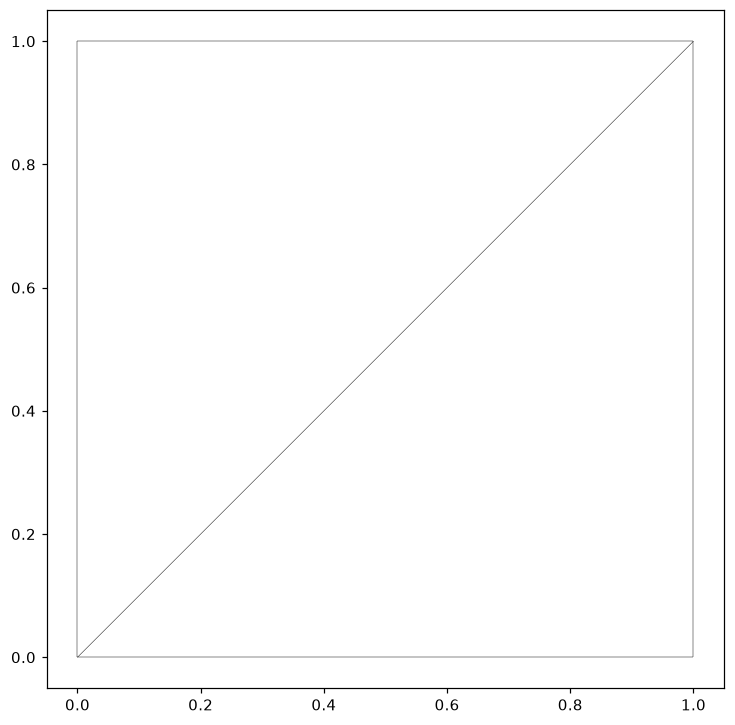

In [10]:
ds.plot_outline()
show()

## 8. A data map

Selafin's headline variable is **WATER DEPTH**. We map it directly — these are real TELEMAC output values, varying across the mesh. `plot` renders the first time step by default; the `summary()` table above reported the full range across both steps.

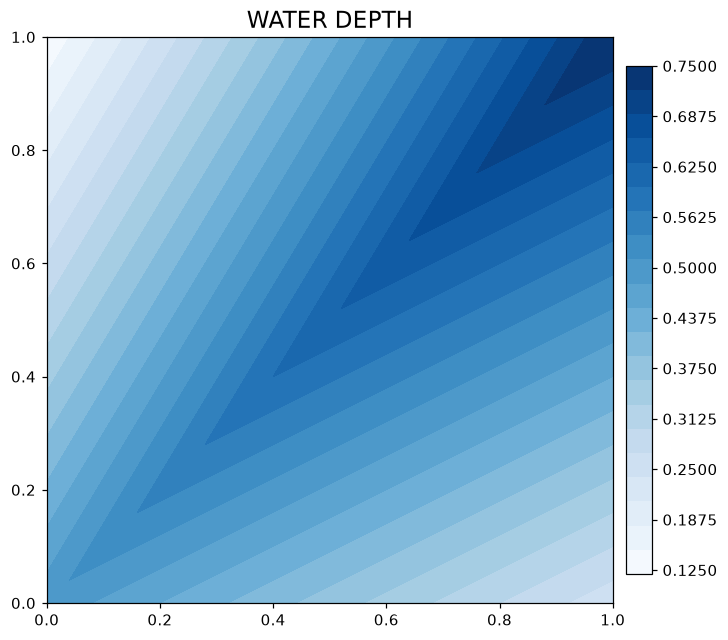

In [11]:
ds.plot('WATER DEPTH', cmap='Blues', colorbar=True, title='WATER DEPTH')
show()

## 9. GIS operations

Because a `UgridDataset` is a first-class `pyramids` object, the full geospatial toolkit works on it directly — no conversion step. Below are several operations, each visualised or interpreted. (Operations that need a source CRS, such as `to_crs`, are skipped here: this sample declares none.)

### 9a. Faces as polygons — `to_geodataframe()`

Every face becomes a shapely polygon in a GeoPandas `GeoDataFrame`, ready for a spatial join, an overlay, or export to any OGR vector format.

In [12]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((0 0, 1 0, 1 1, 0 0))"
1,"POLYGON ((0 0, 1 1, 0 1, 0 0))"


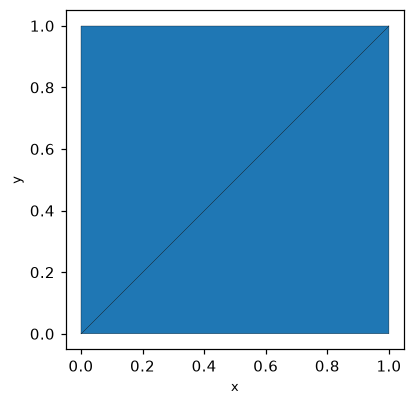

In [13]:
gdf.plot(edgecolor="k", linewidth=0.2, figsize=(5, 4))
plt.gca().set_aspect("equal")
show()

The polygon mosaic is the mesh itself — each cell is now an independent vector feature. That is the bridge from a solver mesh to standard GIS.

### 9b. Outer boundary — `bounding_polygon()` and `exterior_edges()`

`bounding_polygon()` dissolves the faces into a single shapely polygon tracing the mesh outline, and `exterior_edges()` returns the indices of the mesh edges that lie on that boundary — their count is the boundary's edge length.

boundary edges: 4


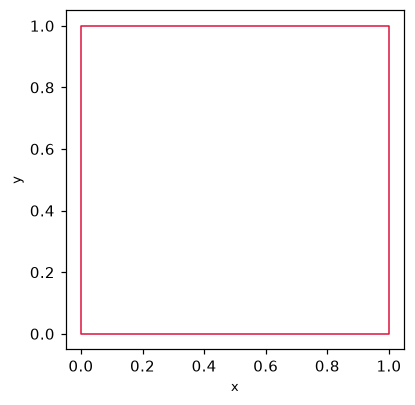

In [14]:
poly = ds.bounding_polygon()
n_boundary = len(ds.exterior_edges())
print('boundary edges:', n_boundary)
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 4))
plt.gca().set_aspect("equal")
show()

The crimson ring is the domain outline; `exterior_edges()` tells us how many element edges trace it — the rest of the edges are interior.

### 9c. Connectivity — `connected_components()`

`connected_components()` labels each face by the connected sub-mesh it belongs to. One unique label means the mesh is a single watertight piece; more than one would reveal detached islands. We attach the labels as a face variable and map them.

faces: 2  components: 1


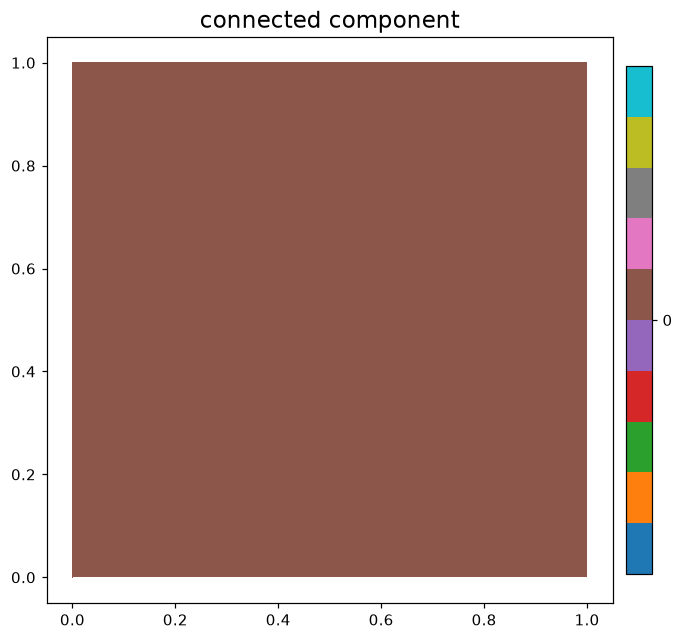

In [15]:
comp = np.asarray(ds.connected_components())
print('faces:', comp.size, ' components:', len(np.unique(comp)))
dc = ds.with_variable("component", comp.astype(float), location="face")
dc.plot("component", cmap="tab10", colorbar=True, title="connected component")
show()

### 9d. Face adjacency — `sparse_adjacency()`

`sparse_adjacency()` returns the face-to-face adjacency as a SciPy sparse matrix (two faces are adjacent when they share an edge). Its sparsity pattern is the dual graph a solver walks; `nnz` counts the directed face-neighbour links.

shape: (2, 2)  nnz: 2


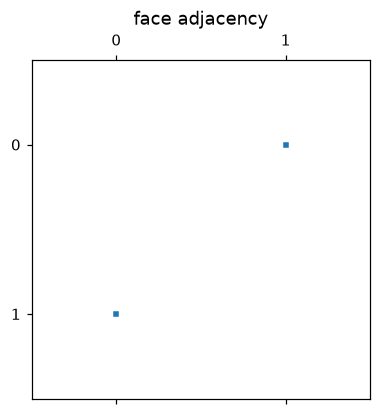

In [16]:
adj = ds.sparse_adjacency()
print('shape:', adj.shape, ' nnz:', adj.nnz)
plt.figure(figsize=(4, 4))
plt.spy(adj, markersize=3)
plt.title("face adjacency")
show()

### 9e. Triangle circumcenters — `circumcenters()`

For a triangular mesh, `circumcenters()` returns the circumcircle centre of each face (shape `(2, n_face)`) — the sample points of the dual Voronoi mesh that finite-volume schemes use. We scatter them over the wireframe.

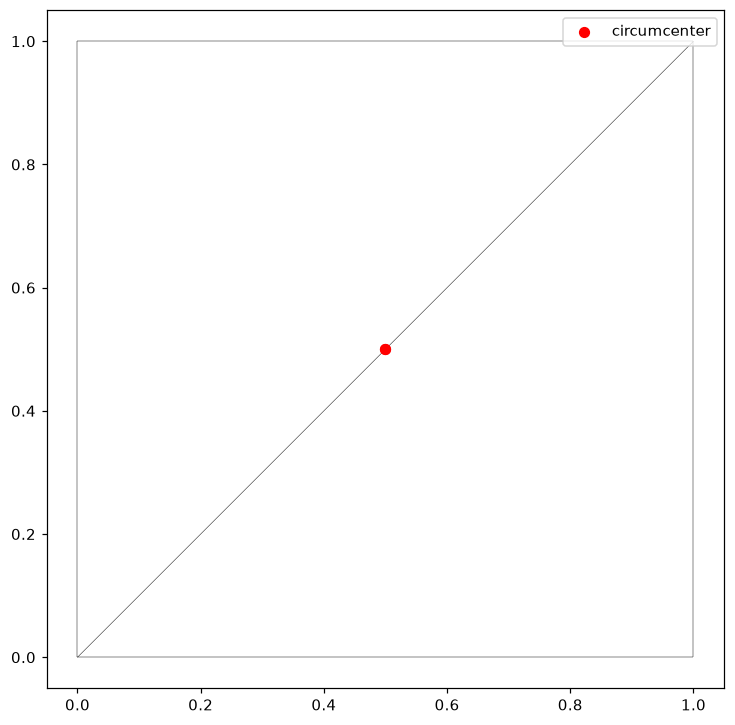

In [17]:
cc = np.asarray(ds.circumcenters())
ds.plot_outline()
plt.scatter(cc[0], cc[1], c="red", s=40, zorder=5, label="circumcenter")
plt.legend()
show()

### 9f. Clip to a sub-region — `crop()`

`crop(bbox=...)` clips the mesh — and the depth field with it — to a bounding box. We keep the lower-left quarter.

faces after crop: 0 of 2


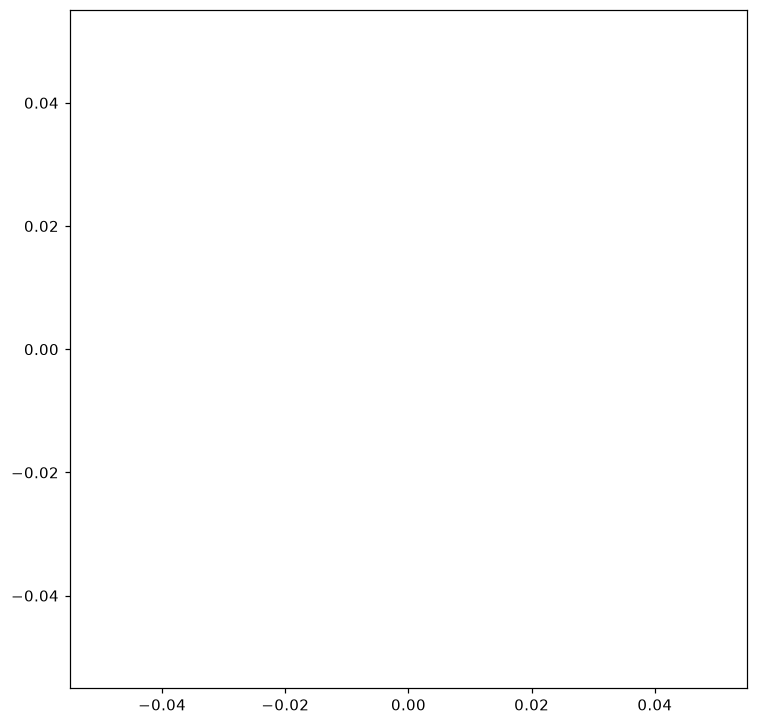

In [18]:
b = ds.bounds
sub = ds.crop(bbox=(b[0], b[1], (b[0]+b[2])/2, (b[1]+b[3])/2))
print('faces after crop:', sub.n_face, 'of', ds.n_face)
sub.plot_outline()
show()

### 9g. Round-trip through UGRID NetCDF — `to_file()` / `to_xarray()`

`to_file(..., driver='ugrid')` writes the mesh to the CF/UGRID NetCDF convention — the lossless lingua franca every tool in the stack reads back. We write it, re-read it, and confirm the topology survived. `to_xarray()` hands the same content to the xarray ecosystem in memory.

In [19]:
import tempfile
out = Path(tempfile.mkdtemp()) / 'roundtrip.nc'
ds.to_file(out, driver="ugrid")
back = UgridDataset.read_file(out, driver="ugrid")
print('re-read nodes/faces:', back.n_node, back.n_face)
ds.to_xarray()

re-read nodes/faces: 4 2


<xarray.Dataset> Size: 180B
Dimensions:            (mesh2d_scalar: 1, mesh2d_nNodes: 4, mesh2d_nFaces: 2,
                        mesh2d_nMaxFaceNodes: 3, time: 2, n_node: 4)
Dimensions without coordinates: mesh2d_scalar, mesh2d_nNodes, mesh2d_nFaces,
                                mesh2d_nMaxFaceNodes, time, n_node
Data variables:
    mesh2d             (mesh2d_scalar) int32 4B 0
    mesh2d_node_x      (mesh2d_nNodes) float64 32B 0.0 1.0 1.0 0.0
    mesh2d_node_y      (mesh2d_nNodes) float64 32B 0.0 0.0 1.0 1.0
    mesh2d_face_nodes  (mesh2d_nFaces, mesh2d_nMaxFaceNodes) int64 48B 1 2 ... 4
    WATER DEPTH        (time, n_node) float64 64B 0.5 0.25 0.75 ... 1.75 1.125
Attributes:
    Conventions:  CF-1.8 UGRID-1.0

## 10. Takeaway

The `selafin` driver reads a TELEMAC mesh-and-results file in one call: topology becomes a `Mesh2d`, each stored field becomes a mappable data variable, and the dataset then supports the full GIS toolkit — vectorise, clip, inspect connectivity, round-trip to UGRID NetCDF.